# MLPilot on the Titanic data

This notebook takes the classic Titanic passenger list from raw CSV to a monitored model, one
MLPilot stage at a time:

| | Stage | What you'll see |
|---|---|---|
| 1 | Load & check | ingestion, profiling, a 0-100 quality score, a data contract |
| 2 | Understand | statistical tests and automatic insights |
| 3 | Prepare | the cleaning pipeline, a leak-checked split, a poisoned-data check |
| 4 | Model | AutoML, held-out evaluation with confidence intervals |
| 5 | Trust | explanations, error slices, fairness, robustness, prediction sets, a model card |
| 6 | Ship | experiment tracking, the model registry, a REST API with feedback |
| 7 | Watch | drift and accuracy estimated before labels arrive |

**Install:** `pip install dataspoof-mlpilot` (import name `mlpilot`). The notebook needs no
other extras; charts use matplotlib. It runs in about 3 minutes on a laptop.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

import mlpilot as ac
from mlpilot import stats
from mlpilot.robustness import robustness_report
from mlpilot.poisoning import poisoning_report

warnings.filterwarnings("ignore", category=ac.MLPilotWarning)    # keep the output readable
pl.Config.set_tbl_rows(12)
OUT = Path("titanic_outputs")              # everything this notebook writes goes here
OUT.mkdir(exist_ok=True)
from importlib.metadata import version
print("MLPilot", version("dataspoof-mlpilot"), "| Polars", pl.__version__)

MLPilot 2.1.0 | Polars 2.1.0


## 1 · Load and check the data

`ac.ingest` reads a file, URL, database or cloud path, infers proper types and records a
fingerprint of exactly what was loaded. The notebook uses a local `titanic.csv` if there is one,
and otherwise reads the public copy over HTTP.

In [2]:
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
local = next((p for p in (Path("titanic.csv"), Path("../titanic.csv")) if p.exists()), None)

result = ac.ingest(str(local) if local else URL, name="titanic")
df = result.data
print(result.summary())
df.head()

Ingested titanic from ..\titanic.csv: 891 rows x 12 columns in 0.03s


PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
i64,i64,i64,str,str,f64,i64,i64,str,f64,str,str
1,0,3,"""Braund, Mr. Owen Harris""","""male""",22.0,1,0,"""A/5 21171""",7.25,null,"""S"""
2,1,1,"""Cumings, Mrs. John Bradley (Fl…","""female""",38.0,1,0,"""PC 17599""",71.2833,"""C85""","""C"""
3,1,3,"""Heikkinen, Miss. Laina""","""female""",26.0,0,0,"""STON/O2. 3101282""",7.925,null,"""S"""
4,1,1,"""Futrelle, Mrs. Jacques Heath (…","""female""",35.0,1,0,"""113803""",53.1,"""C123""","""S"""
5,0,3,"""Allen, Mr. William Henry""","""male""",35.0,0,0,"""373450""",8.05,null,"""S"""


**Profile and quality score.** Every check feeds one score from 0 to 100, split by dimension
(completeness, validity, consistency, uniqueness) and by column, so you know where to look first.

In [3]:
prof = ac.profile(df)
q = prof.quality
print(f"{prof.rows} rows x {prof.columns} columns, {prof.missing_pct:.1f}% of cells missing")
print(f"Quality score {q.score:.1f}/100 (grade {q.grade})")
print("Dimensions:", {k: round(v, 1) for k, v in q.dimensions.items()})
print("Weakest columns:", q.weakest_columns(k=3))
q.to_frame().select("severity", "check", "column", "title").head(8)

891 rows x 12 columns, 8.1% of cells missing
Quality score 97.2/100 (grade A)
Dimensions: {'completeness': 91.9, 'uniqueness': 100.0, 'validity': 100.0, 'consistency': 99.9}
Weakest columns: [('Cabin', 50.9), ('Age', 89.3)]


severity,check,column,title
str,str,str,str
"""high""","""missing_values""","""Cabin""","""Missing values · Cabin"""
"""high""","""outliers""","""Fare""","""Outliers · Fare"""
"""medium""","""missing_values""","""Age""","""Missing values · Age"""
"""medium""","""outliers""","""SibSp""","""Outliers · SibSp"""
"""low""","""missing_values""","""Embarked""","""Missing values · Embarked"""
"""low""","""possible_identifier""","""PassengerId""","""Possible identifier · Passenge…"
"""low""","""possible_identifier""","""Name""","""Possible identifier · Name"""
"""low""","""outliers""","""Age""","""Outliers · Age"""


**A data contract** captures what "good" Titanic data looks like (types, ranges, allowed values,
null limits). Saved as YAML, it can validate every future batch. Here a batch with a negative
age and an unknown port of embarkation is flagged.

Inferred rules start as *warnings*, so the batch still "passes" while the problems are reported. Set
a rule's severity to `error` in the YAML to block such a load (`ac.ingest(..., contract=...)`).

In [4]:
contract = ac.Contract.infer(df, name="titanic")
contract.to_yaml(OUT / "titanic_contract.yml")

bad_batch = df.head(5).with_columns(
    pl.when(pl.int_range(pl.len()) == 0).then(-4.0).otherwise(pl.col("Age")).alias("Age"),
    pl.when(pl.int_range(pl.len()) == 1).then(pl.lit("X")).otherwise(pl.col("Embarked")).alias("Embarked"),
)
check = contract.validate(bad_batch)
print(f"passed: {check.passed} | errors: {len(check.errors)} | warnings: {len(check.warnings)}")
check.to_frame().filter(~pl.col("passed")).select("rule", "column", "severity", "failed", "message")

passed: True | errors: 0 | warnings: 2


rule,column,severity,failed,message
str,str,str,i64,str
"""min""","""Age""","""warn""",1,"""1 values below 0.42"""
"""allowed""","""Embarked""","""warn""",1,"""1 values outside the allowed s…"


## 2 · Understand it

A first look at the famous pattern: survival by sex and passenger class.

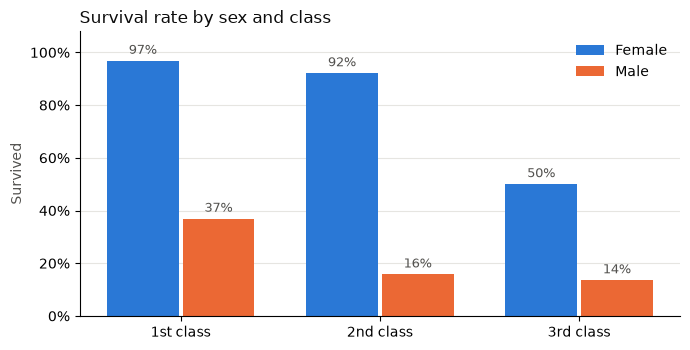

In [5]:
rates = (df.group_by("Sex", "Pclass").agg(pl.col("Survived").mean().alias("rate"), pl.len().alias("n"))
           .sort("Pclass", "Sex"))
classes = [1, 2, 3]
colors = {"female": "#2a78d6", "male": "#eb6834"}            # categorical slots 1 and 2
fig, ax = plt.subplots(figsize=(7, 3.6))
width = 0.36
for i, sex in enumerate(["female", "male"]):
    vals = [rates.filter((pl.col("Sex") == sex) & (pl.col("Pclass") == c))["rate"][0] for c in classes]
    xs = [c + (i - 0.5) * (width + 0.02) for c in classes]
    bars = ax.bar(xs, vals, width=width, color=colors[sex], label=sex.capitalize())
    for x, v in zip(xs, vals):
        ax.text(x, v + 0.015, f"{v:.0%}", ha="center", va="bottom", fontsize=9, color="#52514e")
ax.set_xticks(classes, ["1st class", "2nd class", "3rd class"])
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("Survived", color="#52514e")
ax.set_title("Survival rate by sex and class", loc="left", fontsize=12, color="#0b0b0b")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

**Is it significant?** `stats` picks the right test for the data (checking normality and equal
variances first) and reports an effect size and a plain-English reading, not just a p-value.

In [6]:
for res in (stats.chi_square(df, "Sex", "Survived"),
            stats.chi_square(df, "Pclass", "Survived"),
            stats.compare_groups(df, value="Fare", group="Survived"),
            stats.compare_groups(df.drop_nulls("Age"), value="Age", group="Survived")):
    print(res.summary(), "\n")

chi-square test of independence: statistic 263.1, p = 3.712e-59, cramers_v = 0.543 (large)
  assumptions: cells with expected count < 5: 0%
  -> 'Sex' and 'Survived' are associated (large association) 

chi-square test of independence: statistic 102.9, p = 4.549e-23, cramers_v = 0.337 (medium)
  assumptions: cells with expected count < 5: 0%
  -> 'Pclass' and 'Survived' are associated (medium association) 

Mann-Whitney U: statistic 5.781e+04, p = 4.553e-22, rank_biserial = -0.384 (medium)
  assumptions: normal (per group): no, equal variances (Levene): no, chosen: rank-based
  -> 'Fare' by 'Survived': 0 tends to be lower than 1 (significant, medium effect) 

Welch's t-test: statistic 2.046, p = 0.04119, hedges_g = 0.157 (negligible), 95% CI [0.09158, 4.473]
  assumptions: normal (per group): yes, equal variances (Levene): yes, chosen: parametric
  -> 'Age' by 'Survived': mean of 0 is 2.282 higher than 1 (statistically significant, negligible effect) 



**Automatic insights** rank the strongest findings about the target in plain English.

In [7]:
for ins in ac.find_insights(df, target="Survived", max_insights=6):
    print("-", ins.headline)

- The rate of Survived = 1 is 19% when Sex is male, vs 74% otherwise (0.3x); 577 rows.
- The rate of Survived = 1 is 24% when Pclass is 3, vs 56% otherwise (0.4x); 491 rows.
- The rate of Survived = 1 is 63% when Pclass is 1, vs 31% otherwise (2.1x); 216 rows.
- The rate of Survived = 1 is 58% when Fare >= 31, vs 32% otherwise (1.8x); 225 rows.
- The rate of Survived = 1 is 20% when Fare < 7.91, vs 45% otherwise (0.4x); 223 rows.
- The rate of Survived = 1 is 34% when Embarked is S, vs 51% otherwise (0.7x); 644 rows.


## 3 · Prepare

**Cleaning.** The default pipeline fixes types, text, inconsistent categories, outliers and
missing values. It is *fitted* once and replays exactly the same way on new data, and it saves
as JSON for production.

In [8]:
cleaner = ac.default_cleaning_pipeline()
clean = cleaner.fit_transform(df.drop("Survived"))
cleaner.save(OUT / "cleaning_pipeline.json")
print(cleaner.report_.summary() if hasattr(cleaner.report_, "summary") else cleaner.report_)
print("Missing cells before:", df.drop("Survived").null_count().sum_horizontal()[0],
      "| after:", clean.null_count().sum_horizontal()[0])

Pipeline 'automated-cleaning' · fit · 11 steps · 0.02s · rows 891→891 · cols 11→9 · nulls 866→0
  #  step                                   rows      cols          nulls     time
  1  replace_disguised_missing           891→891     11→11        866→866      2ms
  2  normalize_whitespace                891→891     11→11        866→866      3ms
  3  normalize_unicode                   891→891     11→11        866→866      2ms
  4  convert_numeric_text                891→891     11→11        866→866      3ms
  5  parse_dates                         891→891     11→11        866→866      3ms
  6  drop_duplicates                     891→891     11→11        866→866      0ms
  7  drop_columns                        891→891      11→8        866→179      2ms
  8  impute                              891→891       8→9          179→0      2ms
  9  group_rare_categories               891→891       9→9            0→0      1ms
 10  clip_outliers                       891→891       9→9            0→0 

**A leak-checked split.** For classification the split is stratified by the target, and it is
checked afterwards for duplicate rows across sides and classes missing from training.

In [9]:
split = ac.split_data(df, target="Survived", test_size=0.2, seed=7)
train, test = split.train, split.test
print(split.report())

Split strategy: stratified by 'Survived'
  train      713 rows (80%)
  test       178 rows (20%)
  train classes: 0=0.62, 1=0.38
  test classes: 0=0.62, 1=0.38
  Leakage checks: passed


**Is the training data trustworthy?** `poisoning_report` looks for likely label errors,
identical passengers with different outcomes, backdoor-style triggers and outliers.

On the Titanic, many outcomes simply can't be predicted from the columns: a third-class man who
survived, a first-class woman who didn't. Confident learning marks such rows as "likely
mislabelled", so a share like this is expected here. Treat them as rows to review, not as errors.
What matters for poisoning is the rest of the report: no conflicting duplicates and no trigger
patterns. On clean, predictable data the share is far lower.

In [10]:
pois = poisoning_report(train, "Survived")
print(pois.summary())
pois.suspicious.head(5)

Poisoning / label-quality check (classification, 713 rows): 96 suspicious rows (13.5%)
  likely label errors: 89
  identical rows with different labels: 0
  outliers: 8
  no backdoor-trigger patterns found


row,score,reasons
i64,f64,str
19,2.454271,"""likely mislabelled; outlier"""
537,1.999809,"""likely mislabelled"""
393,1.999781,"""likely mislabelled"""
404,1.99977,"""likely mislabelled"""
598,1.999446,"""likely mislabelled"""


## 4 · Model

`AutoML` detects the task, guards against leakage, engineers features (titles in names,
ticket prefixes, encodings…), searches model families within a time budget and builds an
ensemble. Every step is cross-validated on the training split only.

In [11]:
model = ac.AutoML("Survived", time_budget=60, verbose=False, seed=7).fit(train)
print(model.summary())
model.leaderboard_.select("model", "score", "std", "seconds").head(6)

AutoML: binary 'Survived' | 'Survived' has 2 distinct values
  713 rows x 8 features | metric roc_auc | 5-fold stratified CV | 45 trials in 57.67s
  Best: ensemble  cv roc_auc = 0.8859 ± 0.0307
  Best per model:
     1. ensemble                 0.8859 ± 0.0307
     2. logistic_regression      0.8831 ± 0.0277
     3. xgboost                  0.8759 ± 0.0402
     4. random_forest            0.8755 ± 0.0320
     5. hist_gradient_boosting   0.8620 ± 0.0361
     6. lightgbm                 0.8589 ± 0.0334
     7. knn                      0.8589 ± 0.0157
     8. extra_trees              0.8578 ± 0.0345
     9. baseline                 0.5000 ± 0.0000


model,score,std,seconds
str,f64,f64,f64
"""ensemble""",0.885863,0.030667,5.792
"""logistic_regression""",0.883073,0.02773,0.081
"""logistic_regression""",0.883073,0.02773,0.096
"""logistic_regression""",0.883036,0.027236,0.073
"""logistic_regression""",0.883031,0.027764,0.085
"""logistic_regression""",0.882997,0.026788,0.071


In [12]:
rep = ac.evaluate_model(model, test)
m, ci = rep.metrics, rep.confidence_intervals
for k in ("accuracy", "roc_auc", "f1"):
    if k in m:
        lo, hi = ci.get(k, (None, None))
        band = f"  (95% CI {lo:.3f}-{hi:.3f})" if lo is not None else ""
        print(f"{k:>9}: {m[k]:.3f}{band}")
rep.confusion_matrix

 accuracy: 0.826  (95% CI 0.764-0.871)
  roc_auc: 0.875  (95% CI 0.811-0.922)
       f1: 0.767


actual,pred_0,pred_1
str,i64,i64
"""0""",96,14
"""1""",17,51


## 5 · Trust

**Why does it predict that?** SHAP values, computed in-house with no extra install, give the
global drivers and a reason for any single passenger.

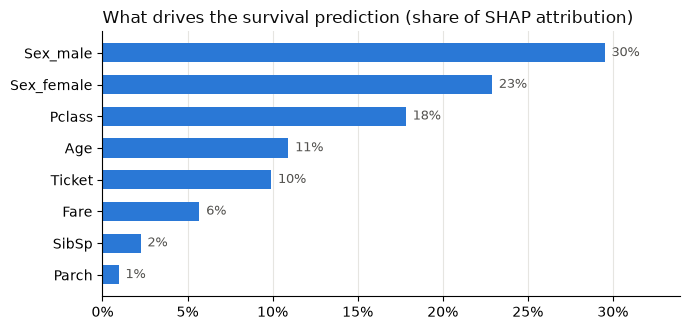

P(Survived = 1) = 0.3055 (average 0.4139): Ticket = 0.4403 (+0.141), Sex_male = 1 (-0.11), Sex_female = 0 (-0.0863), SibSp = 1 (-0.0225), other features -0.0312


In [13]:
exp = model.explain(test, rows=120)
imp = exp.global_importance().head(8)
fig, ax = plt.subplots(figsize=(7, 3.4))
feats, share = imp["feature"].to_list()[::-1], imp["share"].to_list()[::-1]
ax.barh(feats, share, color="#2a78d6", height=0.6)
for y, v in enumerate(share):
    ax.text(v + 0.004, y, f"{v:.0%}", va="center", fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0, max(share) * 1.15)
ax.set_title("What drives the survival prediction (share of SHAP attribution)", loc="left", fontsize=12,
             color="#0b0b0b")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
print(exp.explain_row(0, top=4))

**Where is it wrong?** Error analysis finds the passenger segments where the model
underperforms, with a significance test so you don't chase noise.

In [14]:
print(model.error_analysis(test).summary(top=5))

Error analysis of ensemble on 178 rows - overall error rate 17.4%
  No segment is significantly worse than average.
    weakest: Pclass = 1 & Fare in [15.85, 40.14) error rate 50.0% (2.9x) n=12
    weakest: PassengerId in [1, 171.2)         error rate 27.8% (1.6x) n=36
    weakest: Age in [24, 31.6)                 error rate 27.3% (1.6x) n=33
  Most common mistakes: 1 -> 0 (17), 0 -> 1 (14)


**Fairness.** On the Titanic, "women and children first" makes sex a *real* driver of survival,
so large gaps between groups are expected here. The point is the mechanism: the same check flags
disparate impact on a loan or hiring model, where such a gap would be a problem.

In [15]:
fair = model.fairness(test, sensitive=["Sex"])
print(fair.summary())

Fairness of ensemble on 178 rows (positive = 1): 4 flag(s)
  Sex  [used as a model feature]
    demographic_parity_difference    0.747
    disparate_impact_ratio           0.114
    equal_opportunity_difference     0.608
    equalized_odds_difference        0.608
    predictive_parity_difference     0.069
    accuracy_difference              0.045
    ! demographic_parity_difference 0.747 > 0.1: gap in the share of each group predicted positive
    ! disparate_impact_ratio 0.114 < 0.8: lowest / highest group selection rate (four-fifths rule)
    ! equal_opportunity_difference 0.608 > 0.1: gap in true-positive rate (recall) between groups
    ! equalized_odds_difference 0.608 > 0.1: largest gap in true- or false-positive rate between groups
    - Actual positive rates differ by 0.50 between groups, so part of the selection-rate gap reflects the data; equal opportunity / equalized odds compare groups on equal footing.
    - This attribute (or an encoding of it) is an input to the model.

**Robustness and uncertainty.**
- `robustness_report` measures how easily predictions flip under noise and small adversarial
  changes.
- `predict_set` gives conformal prediction sets: two labels means "not sure", with a 90% coverage
  guarantee.

In [16]:
print(robustness_report(model, test, n=100).summary())

Robustness (binary, 100 rows)
  noise 1% sd -> 1.0% flip rate, 5% sd -> 1.0% flip rate, 10% sd -> 1.0% flip rate
  adversarial: 9% of 100 rows changed within 2.0 sd; median distance 0.3 sd; most used feature: PassengerId
  rows fooled within: 0.1 sd -> 3%, 0.25 sd -> 3%, 0.5 sd -> 7%, 1 sd -> 9%
  most sensitive features: Sex (81%), Age (20%), Pclass (17%), Ticket (9%), SibSp (5%)
  extreme inputs: handled


In [17]:
sets = model.predict_set(test.head(8), coverage=0.9)
test.head(8).select("Name", "Sex", "Age", "Pclass", "Survived").with_columns(prediction_set=sets)

Name,Sex,Age,Pclass,Survived,prediction_set
str,str,f64,i64,i64,list[i64]
"""Braund, Mr. Owen Harris""","""male""",22.0,3,0,[0]
"""Moran, Mr. James""","""male""",null,3,0,[0]
"""McCarthy, Mr. Timothy J""","""male""",54.0,1,0,[0]
"""Hewlett, Mrs. (Mary D Kingcome…","""female""",55.0,2,1,[1]
"""Vander Planke, Mrs. Julius (Em…","""female""",31.0,3,0,[1]
"""Masselmani, Mrs. Fatima""","""female""",null,3,1,[1]
"""Todoroff, Mr. Lalio""","""male""",null,3,0,[0]
"""Mamee, Mr. Hanna""","""male""",null,3,1,[0]


**Model card.** One call writes documentation that compliance and reviewers can read: intended
use, data, metrics with intervals, drivers, fairness, limitations.

In [18]:
card = model.model_card(test, name="Titanic survival", intended_use="Teaching example; not for decisions about people.")
card.save(OUT / "titanic_model_card.md")
card.save(OUT / "titanic_model_card.html")
print((OUT / "titanic_model_card.md").read_text(encoding="utf-8")[:900], "...")

Generated 2026-11-09T20:28:22 by MLPilot 2.1.0


## Model details

| | |
|---|---|
| **Task** | Binary classification of `Survived` |
| **Version** | 1.0 |
| **Classes** | 0, 1 |
| **Algorithm** | ensemble (soft-voting: logistic_regression, xgboost, random_forest) |
| **Selection metric** | roc_auc (5-fold stratified CV) |
| **Cross-validated score** | 0.8859 ± 0.0307 |
| **Baseline score** | 0.5000 |
| **Search** | 45 trials in 57.67s |
| **Task detection** | 'Survived' has 2 distinct values |


## Intended use

Teaching example; not for decisions about people.


## Training data

| | |
|---|---|
| **Rows** | 713 |
| **Features** | 8 (8 numeric, 0 categorical) |
| **Preprocessing** | function → function → function → convert_numeric_text → parse_dates → drop_duplicates → drop_columns → impute → group_rare_categories → clip_outliers → drop_collinear → datetime_features → text_embeddings → ...


## 6 · Ship

**Track and register.** Runs record parameters, metrics, the exact data fingerprint and
artifacts. The registry versions models through `dev -> qa -> staging -> production`, with
metric gates on promotion.

In [19]:
tracker = ac.Tracker(OUT / "runs", experiment="titanic")
with tracker.start_run("automl-60s") as run:
    run.log_automl(model, train, test)

registry = ac.ModelRegistry(OUT / "registry")
v = registry.register(model, "titanic", run=run, description="AutoML, 60 s budget")
registry.promote("titanic", v.version, "qa")
registry.promote("titanic", v.version, "production", require={"cv_roc_auc": 0.80})
registry.models()

name,versions,latest,production,staging,qa,dev,task,target
str,i64,i64,i64,i64,i64,i64,str,str
"""titanic""",4,4,4,null,null,null,"""binary""","""Survived"""


**Serve it.** `make_app` is a production-ready REST API: API keys, metrics for Prometheus,
canary and shadow rollouts, hot reload, and a feedback endpoint. Here it is called in-process.
In production you run `mlpilot serve` or the generated Docker image.

In [20]:
import io

app = ac.deploy.app_from_registry(registry, "titanic")

def call(method, path, body=None):
    raw = json.dumps(body).encode() if body is not None else b""
    status = {}
    resp = b"".join(app({"REQUEST_METHOD": method, "PATH_INFO": path, "CONTENT_LENGTH": str(len(raw)),
                         "CONTENT_TYPE": "application/json", "wsgi.input": io.BytesIO(raw)},
                        lambda s, h: status.update(code=s)))
    return status["code"], json.loads(resp) if resp[:1] == b"{" else resp.decode()

passengers = [
    {"PassengerId": 1001, "Pclass": 1, "Name": "Allen, Miss. Elisabeth Walton", "Sex": "female", "Age": 29, "SibSp": 0, "Parch": 0,
     "Ticket": "24160", "Fare": 211.34, "Cabin": "B5", "Embarked": "S"},
    {"PassengerId": 1002, "Pclass": 3, "Name": "Smith, Mr. John", "Sex": "male", "Age": 24, "SibSp": 0, "Parch": 0,
     "Ticket": "A/5 3902", "Fare": 7.25, "Cabin": None, "Embarked": "S"},
]
status, out = call("POST", "/predict", {"records": passengers})
print(status, "->", out["predictions"], [round(p["1"], 2) for p in out["probabilities"]])

# later, the true outcome arrives: send it back with the prediction id
status, fb = call("POST", "/feedback", {"prediction_id": out["prediction_ids"][0], "label": 1})
print("feedback:", fb)

200 OK -> [1, 0] [0.99, 0.1]
feedback: {'accepted': 1, 'matched': 1, 'unknown_ids': []}


## 7 · Watch

`Monitor` keeps a statistical baseline (no raw data) and checks each new batch. Without labels,
it still *estimates* accuracy from the model's calibrated confidence, so a drop is visible
weeks before outcomes are known.

Below, a simulated batch skews older and pays more. It has no labels yet.

What to expect: the drift checks fire on `Age` and `Fare`, and the prediction distribution
shifts. The *estimated* score may still rise, because older, wealthier passengers are easy cases
for this model. Drift says "the model hasn't seen data like this"; the estimate says how confident it is on
it. You want both.

In [21]:
monitor = ac.Monitor(model, test, name="titanic")
monitor.save(OUT / "monitor.json")

shifted = (test.drop("Survived")
           .with_columns((pl.col("Age") + 25).alias("Age"), (pl.col("Fare") * 4).alias("Fare")))
report = monitor.check(shifted)
print(report.summary())
perf = report.performance
print()
print(f"Estimated {perf['metric']} without labels: {perf['current']:.3f} "
      f"(90% interval {perf['interval'][0]:.3f}-{perf['interval'][1]:.3f}), reference {perf['reference']:.3f}")

Monitoring check 2026-11-09T14:58:39+00:00: 178 rows - warnings
  [warning] data_drift: major drift in ['Fare', 'Age']
  Performance: roc_auc 0.8959 (reference 0.8747)
  Prediction drift: PSI 0.194 (moderate)
  Drift: 2 of 8 column(s) with major drift, 0 moderate (178 rows vs 178 reference)
    [major] Fare: PSI 4.827, mean 38.02 -> 152.1
    [major] Age: PSI 2.790, mean 30.11 -> 55.11

Estimated roc_auc without labels: 0.896 (90% interval 0.854-0.936), reference 0.875


## Where to go next

- **Pipelines:** `mlpilot cicd init --provider github --name titanic --data data/titanic.csv
  --target Survived` writes a train -> gate -> register -> release -> deploy pipeline.
- **The Hub:** a multi-user server with single sign-on, approvals and an audit log.
- **Operations:** Grafana dashboards and Prometheus alerts for live models, and lineage via
  OpenLineage.
- **Documentation:** <https://github.com/DataSpoof/dataspoof-mlpilot>

Everything this notebook wrote is in `titanic_outputs/` and can be deleted.